Importing all the libraries to manipulate and analyze the dataset

In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import os, shutil, glob

Need to counts how many normal and pneumonia images are in the train and test folders and prints them, so I can see the size and balance of the data.

In [2]:
baseDir = "chest_xray"
classNames = ["NORMAL", "PNEUMONIA"]

trainCounts = [len(os.listdir(f"{baseDir}/train/{c}")) for c in classNames]
testCounts = [len(os.listdir(f"{baseDir}/test/{c}")) for c in classNames]

print("train:", trainCounts)
print("test:", testCounts)

train: [1341, 3875]
test: [234, 390]


Draws a bar chart of normal vs pneumonia in training which shows the data is imbalanced like many more pneumonia images, which is why class weights are used later.

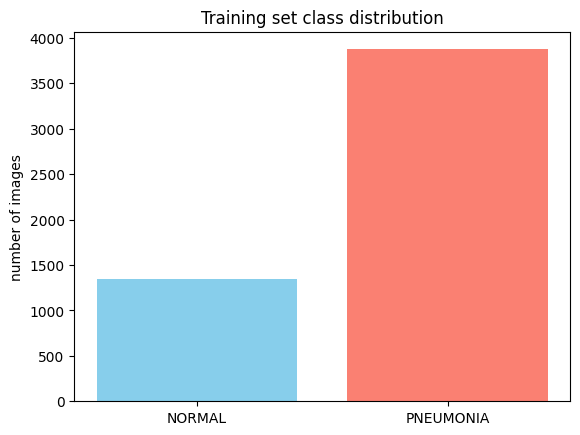

In [3]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(classNames, trainCounts, color=["skyblue", "salmon"])
plt.title("Training set class distribution")
plt.ylabel("number of images")
plt.show()

Putting the train and test counts side by side for each class, so I can see how the data is split between training and testing.

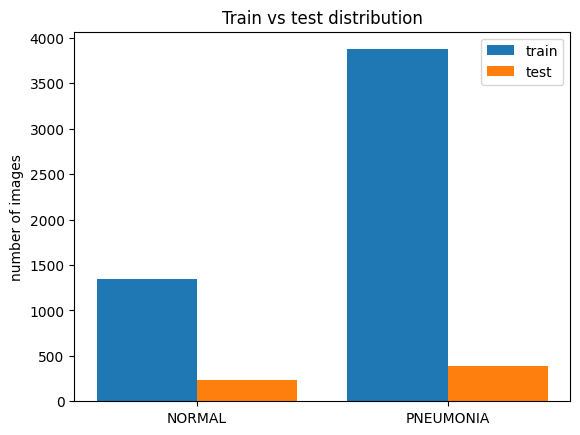

In [4]:
import numpy as np

x = np.arange(len(classNames))
plt.figure()
plt.bar(x - 0.2, trainCounts, 0.4, label="train")
plt.bar(x + 0.2, testCounts, 0.4, label="test")
plt.xticks(x, classNames)
plt.ylabel("number of images")
plt.title("Train vs test distribution")
plt.legend()
plt.show()

shows one normal and one pneumonia X-ray side by side, so I can actually see what the two classes look like and check the labels are correct.

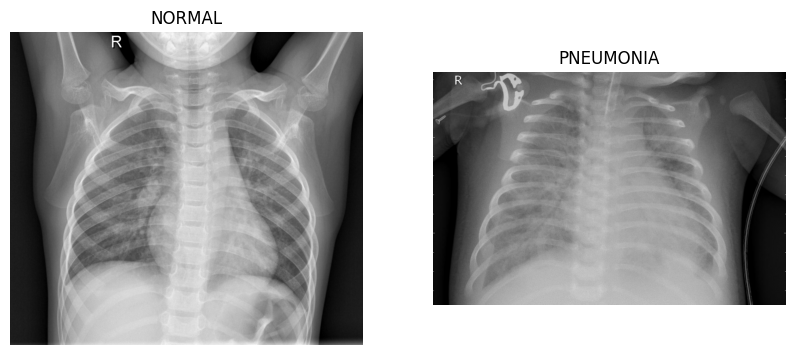

In [5]:
from PIL import Image

plt.figure(figsize=(10, 5))
for i, c in enumerate(classNames):
    folder = f"{baseDir}/train/{c}"
    fileName = os.listdir(folder)[0]
    plt.subplot(1, 2, i + 1)
    plt.imshow(Image.open(os.path.join(folder, fileName)), cmap="gray")
    plt.title(c)
    plt.axis("off")
plt.show()

Plotting the width and height of the images to see the range of image sizes in the dataset

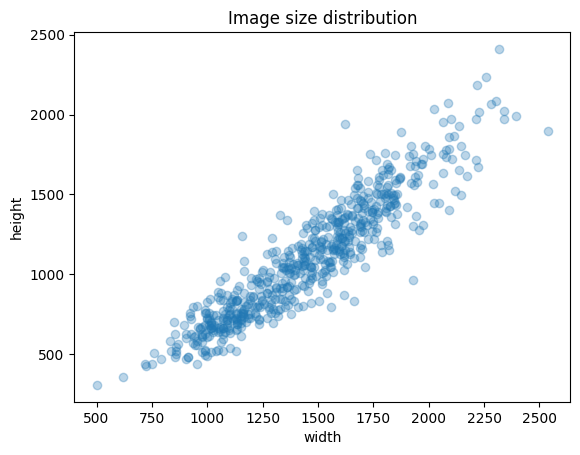

In [6]:
widths, heights = [], []
for c in classNames:
    folder = f"{baseDir}/train/{c}"
    for fileName in os.listdir(folder)[:300]:
        img = Image.open(os.path.join(folder, fileName))
        widths.append(img.size[0])
        heights.append(img.size[1])

plt.figure()
plt.scatter(widths, heights, alpha=0.3)
plt.xlabel("width")
plt.ylabel("height")
plt.title("Image size distribution")
plt.show()

Creating an average image for each class to see the general difference between normal and pneumonia X-rays

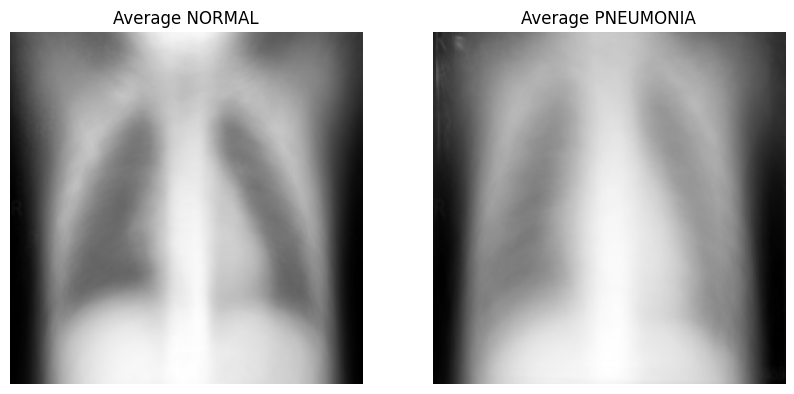

In [7]:
plt.figure(figsize=(10, 5))
for i, cls in enumerate(classNames):
    folder = f"{baseDir}/train/{cls}"
    files = os.listdir(folder)[:200]
    acc = np.zeros((224, 224))
    for f in files:
        img = Image.open(os.path.join(folder, f)).convert("L").resize((224, 224))
        acc += np.array(img)
    acc /= len(files)
    plt.subplot(1, 2, i + 1)
    plt.imshow(acc, cmap="gray")
    plt.title("Average " + cls)
    plt.axis("off")
plt.show()

Sets the folder paths, image size, batch size and seed used through the rest of the notebook.

In [8]:
trainDir = "chest_xray/train"
testDir = "chest_xray/test"

imgSize = (224, 224)
batchSize = 32
seed = 42

Reads the images straight from the folders and turns them into datasets the model can use. It takes 20 percent of the training folder as a validation set, keeps the test folder separate, and gets the labels automatically from the folder names.

In [9]:
trainDs = tf.keras.utils.image_dataset_from_directory(
    trainDir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=imgSize,
    batch_size=batchSize,
    label_mode="binary"
)

valDs = tf.keras.utils.image_dataset_from_directory(
    trainDir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=imgSize,
    batch_size=batchSize,
    label_mode="binary"
)

testDs = tf.keras.utils.image_dataset_from_directory(
    testDir,
    image_size=imgSize,
    batch_size=batchSize,
    label_mode="binary",
    shuffle=False
)

classNames = trainDs.class_names
print(classNames)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
['NORMAL', 'PNEUMONIA']


Changes the pixel values from 0-255 down to 0-1 so training becoming better and adds small random changes like flip, rotate, zoom to the training images only, so the model does not just learn them. prefetch makes training run faster.

In [10]:
normalization = layers.Rescaling(1./255)

dataAugmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

trainDs = trainDs.map(lambda x, y: (dataAugmentation(x), y))
trainDs = trainDs.map(lambda x, y: (normalization(x), y))
valDs = valDs.map(lambda x, y: (normalization(x), y))
testDs = testDs.map(lambda x, y: (normalization(x), y))

trainDs = trainDs.prefetch(tf.data.AUTOTUNE)
valDs = valDs.prefetch(tf.data.AUTOTUNE)
testDs = testDs.prefetch(tf.data.AUTOTUNE)

because there are more pneumonia images than normal, this gives the smaller class like normal more importance during training, so the model does not just keep predicting pneumonia.

In [11]:
normalCount = len(os.listdir("chest_xray/train/NORMAL"))
pneumoniaCount = len(os.listdir("chest_xray/train/PNEUMONIA"))
total = normalCount + pneumoniaCount

classWeights = {
    0: total / (2 * normalCount),
    1: total / (2 * pneumoniaCount)
}

print(classWeights)

{0: 1.9448173005219984, 1: 0.6730322580645162}


creates the baseline CNN and Conv2D and maxpooling layers find features in the X-ray, flatten and dense layers make the decision and dropout helps stop overfitting and the last layer gives one output between 0 and 1  like 0 = normal, 1 = pneumonia.

In [12]:

cnnModel = models.Sequential([
    layers.Input((224, 224, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

cnnModel.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
cnnModel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Trains the basic CNN with class weights and early stopping so it keeps the best version and stops when it stops improving

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

earlyStop = EarlyStopping(patience=3, restore_best_weights=True)

history = cnnModel.fit(
    trainDs,
    validation_data=valDs,
    epochs=15,
    class_weight=classWeights,
    callbacks=[earlyStop]
)

Epoch 1/15


131/131 ━━━━━━━━━━━━━━━━━━━━ 97s 727ms/step - accuracy: 0.7002 - loss: 0.5193 - val_accuracy: 0.9137 - val_loss: 0.2025
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 98s 743ms/step - accuracy: 0.8768 - loss: 0.3098 - val_accuracy: 0.9233 - val_loss: 0.1911
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 98s 741ms/step - accuracy: 0.8991 - loss: 0.2369 - val_accuracy: 0.9223 - val_loss: 0.2011
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 94s 713ms/step - accuracy: 0.9224 - loss: 0.1961 - val_accuracy: 0.9358 - val_loss: 0.1739
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 93s 707ms/step - accuracy: 0.9295 - loss: 0.1867 - val_accuracy: 0.9252 - val_loss: 0.2060
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 93s 708ms/step - accuracy: 0.9327 - loss: 0.1674 - val_accuracy: 0.9530 - val_loss: 0.1224
Epoch 7/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 93s 710ms/step - accuracy: 0.9413 - loss: 0.1588 - val_accuracy: 0.9636 - val_loss: 0.1253
Epoch 8/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 93s 709ms/step - accuracy: 0.9408 - loss: 0.1576 - val

Imports the confusion matrix and classification report from scikit-learn.

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

Runs the trained CNN on the test set and prints the confusion matrix and the precision, recall and F1-score.

In [15]:
yTrue = np.concatenate([y.numpy() for x, y in testDs])
yProb = cnnModel.predict(testDs)
yPred = (yProb > 0.5).astype(int)

print(confusion_matrix(yTrue, yPred))
print(classification_report(yTrue, yPred, target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step
[[100 134]
 [  7 383]]
              precision    recall  f1-score   support

      NORMAL       0.93      0.43      0.59       234
   PNEUMONIA       0.74      0.98      0.84       390

    accuracy                           0.77       624
   macro avg       0.84      0.70      0.72       624
weighted avg       0.81      0.77      0.75       624



These four columns above have different meanings. Precision means, out of all the images the model predicted as a particular class, how many were actually correct. Recall means, out of all the real images of a particular class, how many the model was able to find correctly and  f1 score is a single value that joins both precision and recall to show the complete performance of the model. Support = means the total number of real images present for each class in the test dataset and in this case, there are 10 normal images and 30 pneumonia images, making a total of 40 test images.


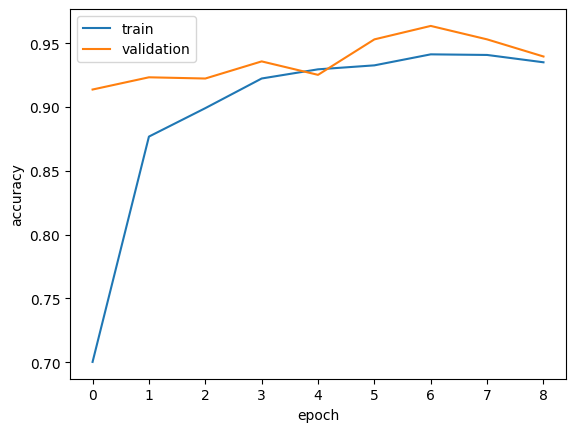

In [16]:
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

Loading ResNet-50 with ImageNet weights, freezes the base, and adds a new head on top

In [17]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import models, layers

resnetBase = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
resnetBase.trainable = False

resnetModel = models.Sequential([
    resnetBase,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

resnetModel.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
resnetModel.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Making ResNet specific datasets using its own preprocess_input function so the input matches how ResNet was trained

In [18]:
from tensorflow.keras.applications.resnet50 import preprocess_input

trainRes = tf.keras.utils.image_dataset_from_directory(
    trainDir, validation_split=0.2, subset="training", seed=seed,
    image_size=imgSize, batch_size=batchSize, label_mode="binary")

valRes = tf.keras.utils.image_dataset_from_directory(
    trainDir, validation_split=0.2, subset="validation", seed=seed,
    image_size=imgSize, batch_size=batchSize, label_mode="binary")

testRes = tf.keras.utils.image_dataset_from_directory(
    testDir, image_size=imgSize, batch_size=batchSize,
    label_mode="binary", shuffle=False)

trainRes = trainRes.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)
valRes = valRes.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)
testRes = testRes.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


Trains the ResNet-50 head with the base frozen, using class weights and early stopping

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

earlyStop = EarlyStopping(patience=3, restore_best_weights=True)

resnetHistory = resnetModel.fit(
    trainRes,
    validation_data=valRes,
    epochs=15,
    class_weight=classWeights,
    callbacks=[earlyStop]
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.9140 - loss: 0.1982 - val_accuracy: 0.9549 - val_loss: 0.1104
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 210s 2s/step - accuracy: 0.9540 - loss: 0.1173 - val_accuracy: 0.9626 - val_loss: 0.0929
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - accuracy: 0.9621 - loss: 0.0997 - val_accuracy: 0.9501 - val_loss: 0.1510
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.9665 - loss: 0.0846 - val_accuracy: 0.9674 - val_loss: 0.1012
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 218s 2s/step - accuracy: 0.9693 - loss: 0.0778 - val_accuracy: 0.9655 - val_loss: 0.0739
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 215s 2s/step - accuracy: 0.9657 - loss: 0.0825 - val_accuracy: 0.9722 - val_loss: 0.0670
Epoch 7/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step - accuracy: 0.9756 - loss: 0.0633 - val_accuracy: 0.9712 - val_loss: 0.0705
Epoch 8/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.9744 - loss: 0.0591 - val_accu

Runs the frozen ResNet-50 on the test set and prints its metrics.

In [20]:
yTrue = np.concatenate([y.numpy() for x, y in testRes])
yProb = resnetModel.predict(testRes)
yPred = (yProb > 0.5).astype(int)

print(confusion_matrix(yTrue, yPred))
print(classification_report(yTrue, yPred, target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step
[[121 113]
 [  2 388]]
              precision    recall  f1-score   support

      NORMAL       0.98      0.52      0.68       234
   PNEUMONIA       0.77      0.99      0.87       390

    accuracy                           0.82       624
   macro avg       0.88      0.76      0.77       624
weighted avg       0.85      0.82      0.80       624



Plotting the ResNet-50 training accuracy and its confusion matrix

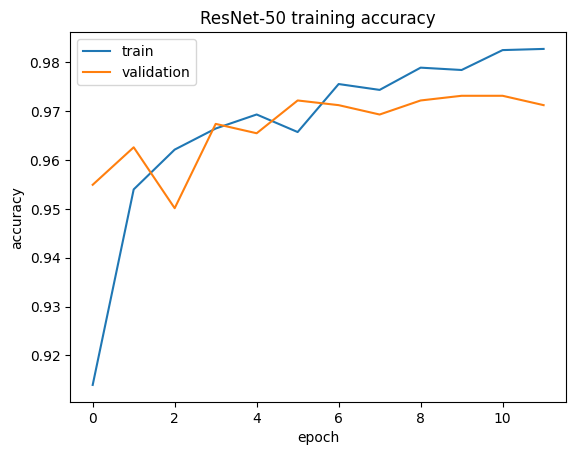

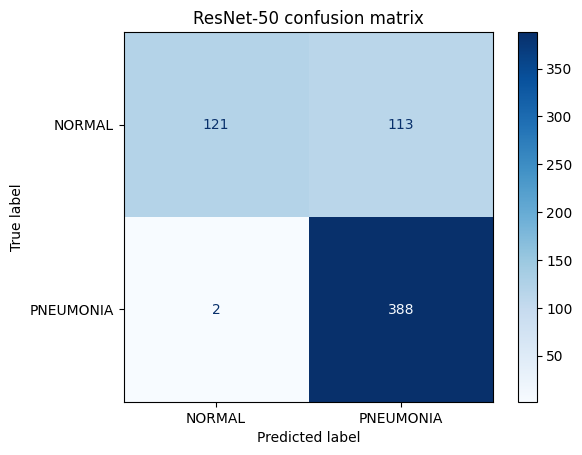

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.plot(resnetHistory.history["accuracy"], label="train")
plt.plot(resnetHistory.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("ResNet-50 training accuracy")
plt.legend()
plt.show()

ConfusionMatrixDisplay.from_predictions(yTrue, yPred, display_labels=["NORMAL", "PNEUMONIA"], cmap="Blues")
plt.title("ResNet-50 confusion matrix")
plt.show()

Unfreezes the top layers of ResNet-50 and trains again with a very small learning rate to adjust the features to chest X-rays

In [22]:
import tensorflow as tf

resnetBase.trainable = True
for layer in resnetBase.layers[:-30]:
    layer.trainable = False

resnetModel.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                    loss="binary_crossentropy", metrics=["accuracy"])

resnetHistory2 = resnetModel.fit(
    trainRes,
    validation_data=valRes,
    epochs=10,
    class_weight=classWeights,
    callbacks=[earlyStop]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 282s 2s/step - accuracy: 0.9669 - loss: 0.0738 - val_accuracy: 0.9789 - val_loss: 0.0567
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.9907 - loss: 0.0273 - val_accuracy: 0.9779 - val_loss: 0.0533
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.9947 - loss: 0.0178 - val_accuracy: 0.9799 - val_loss: 0.0522
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.9986 - loss: 0.0071 - val_accuracy: 0.9827 - val_loss: 0.0508
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 272s 2s/step - accuracy: 0.9993 - loss: 0.0056 - val_accuracy: 0.9866 - val_loss: 0.0513
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.9990 - loss: 0.0037 - val_accuracy: 0.9856 - val_loss: 0.0485
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 273s 2s/step - accuracy: 0.9998 - loss: 0.0030 - val_accuracy: 0.9856 - val_loss: 0.0544
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 288s 2s/step - accuracy: 0.9995 - loss: 0.0024 - val_accu

Runs the fine-tuned ResNet-50 on the test set and prints its metrics and confusion matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step
[[121 113]
 [  3 387]]
              precision    recall  f1-score   support

      NORMAL       0.98      0.52      0.68       234
   PNEUMONIA       0.77      0.99      0.87       390

    accuracy                           0.81       624
   macro avg       0.87      0.75      0.77       624
weighted avg       0.85      0.81      0.80       624



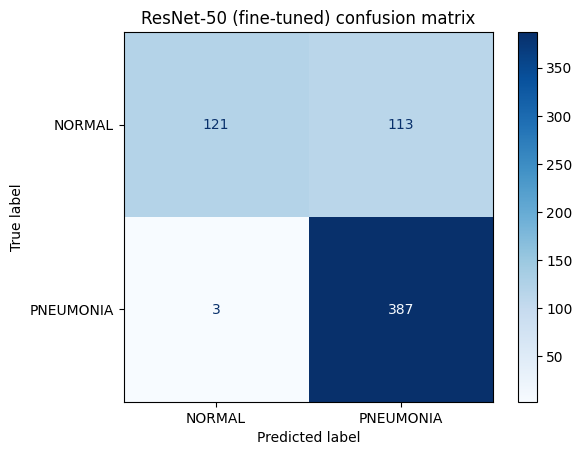

In [23]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

yTrue = np.concatenate([y.numpy() for x, y in testRes])
yProb = resnetModel.predict(testRes)
yPred = (yProb > 0.5).astype(int)

print(confusion_matrix(yTrue, yPred))
print(classification_report(yTrue, yPred, target_names=["NORMAL", "PNEUMONIA"]))

ConfusionMatrixDisplay.from_predictions(yTrue, yPred, display_labels=["NORMAL", "PNEUMONIA"], cmap="Blues")
plt.title("ResNet-50 (fine-tuned) confusion matrix")
plt.show()

Making EfficientNet-specific datasets using its own preprocess_input function

In [24]:
from tensorflow.keras.applications.efficientnet import preprocess_input

trainEff = tf.keras.utils.image_dataset_from_directory(
    trainDir, validation_split=0.2, subset="training", seed=seed,
    image_size=imgSize, batch_size=batchSize, label_mode="binary")

valEff = tf.keras.utils.image_dataset_from_directory(
    trainDir, validation_split=0.2, subset="validation", seed=seed,
    image_size=imgSize, batch_size=batchSize, label_mode="binary")

testEff = tf.keras.utils.image_dataset_from_directory(
    testDir, image_size=imgSize, batch_size=batchSize,
    label_mode="binary", shuffle=False)

trainEff = trainEff.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)
valEff = valEff.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)
testEff = testEff.map(lambda x, y: (preprocess_input(x), y)).prefetch(tf.data.AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


Loading EfficientNet-B0 with ImageNet weights, freezes the base, and adds the same head as before

In [25]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import models, layers

effBase = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
effBase.trainable = False

effModel = models.Sequential([
    effBase,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

effModel.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
effModel.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

trains the efficientNet head with the base frozen, using class weights and early stopping

In [26]:
earlyStop = EarlyStopping(patience=3, restore_best_weights=True)

effHistory = effModel.fit(
    trainEff,
    validation_data=valEff,
    epochs=15,
    class_weight=classWeights,
    callbacks=[earlyStop]
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 93s 647ms/step - accuracy: 0.8922 - loss: 0.2397 - val_accuracy: 0.9473 - val_loss: 0.1248
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 631ms/step - accuracy: 0.9315 - loss: 0.1607 - val_accuracy: 0.9616 - val_loss: 0.1001
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 632ms/step - accuracy: 0.9446 - loss: 0.1323 - val_accuracy: 0.9338 - val_loss: 0.1693
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 629ms/step - accuracy: 0.9456 - loss: 0.1267 - val_accuracy: 0.9425 - val_loss: 0.1438
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 629ms/step - accuracy: 0.9542 - loss: 0.1152 - val_accuracy: 0.9406 - val_loss: 0.1459


Running the frozen EfficientNet on the test set and prints its metrics.

In [ ]:
yTrue = np.concatenate([y.numpy() for x, y in testEff])
yProb = effModel.predict(testEff)
yPred = (yProb > 0.5).astype(int)

print(confusion_matrix(yTrue, yPred))
print(classification_report(yTrue, yPred, target_names=["NORMAL", "PNEUMONIA"]))

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 574ms/step
[[132 102]
 [  5 385]]
              precision    recall  f1-score   support

      NORMAL       0.96      0.56      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.78      0.79       624
weighted avg       0.86      0.83      0.82       624



Plotting the EfficientNet training and validation accuracy.

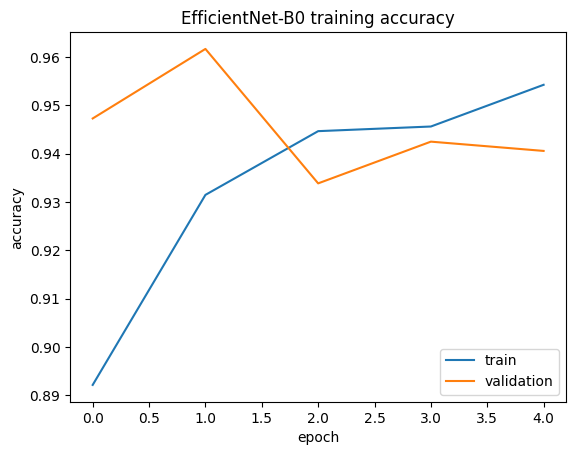

In [28]:
plt.plot(effHistory.history["accuracy"], label="train")
plt.plot(effHistory.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("EfficientNet-B0 training accuracy")
plt.legend()
plt.show()

Shows the confusion matrix of the frozen EfficientNet.

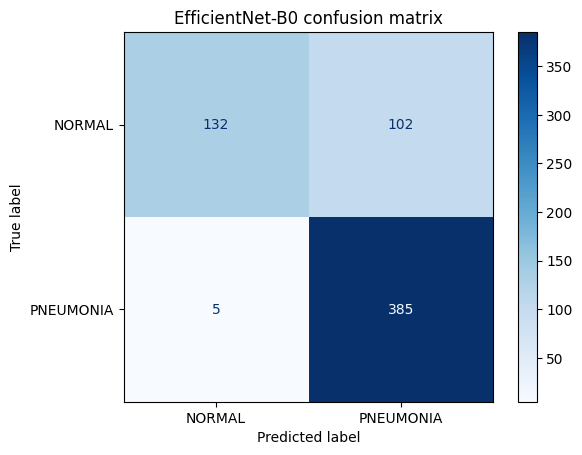

In [29]:
ConfusionMatrixDisplay.from_predictions(yTrue, yPred, display_labels=["NORMAL", "PNEUMONIA"], cmap="Blues")
plt.title("EfficientNet-B0 confusion matrix")
plt.show()

unfreezes the top layers, keeps the BatchNormalization layers frozen, and trains again with a very small learning rate

In [30]:
import tensorflow as tf

effBase.trainable = True
for layer in effBase.layers[:-20]:
    layer.trainable = False
for layer in effBase.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

effModel.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                 loss="binary_crossentropy", metrics=["accuracy"])

effHistory2 = effModel.fit(
    trainEff,
    validation_data=valEff,
    epochs=10,
    class_weight=classWeights,
    callbacks=[earlyStop]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 101s 702ms/step - accuracy: 0.9490 - loss: 0.1242 - val_accuracy: 0.9578 - val_loss: 0.1076
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 91s 693ms/step - accuracy: 0.9528 - loss: 0.1127 - val_accuracy: 0.9597 - val_loss: 0.1059
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 91s 688ms/step - accuracy: 0.9595 - loss: 0.1019 - val_accuracy: 0.9664 - val_loss: 0.0901
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 91s 689ms/step - accuracy: 0.9624 - loss: 0.0909 - val_accuracy: 0.9588 - val_loss: 0.1137
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 91s 689ms/step - accuracy: 0.9585 - loss: 0.0944 - val_accuracy: 0.9674 - val_loss: 0.0854
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 92s 698ms/step - accuracy: 0.9631 - loss: 0.0900 - val_accuracy: 0.9693 - val_loss: 0.0947
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 109s 829ms/step - accuracy: 0.9660 - loss: 0.0816 - val_accuracy: 0.9712 - val_loss: 0.0924
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 107s 810ms/step - accuracy: 0.9660 - loss

runs the fine-tuned EfficientNet on the test set and prints its metrics and confusion matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 612ms/step
[[131 103]
 [  5 385]]
              precision    recall  f1-score   support

      NORMAL       0.96      0.56      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.85      0.83      0.81       624



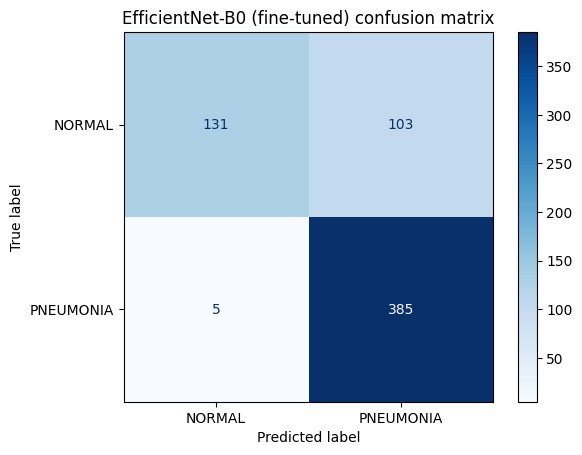

In [31]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

yTrue = np.concatenate([y.numpy() for x, y in testEff])
yProb = effModel.predict(testEff)
yPred = (yProb > 0.5).astype(int)

print(confusion_matrix(yTrue, yPred))
print(classification_report(yTrue, yPred, target_names=["NORMAL", "PNEUMONIA"]))

ConfusionMatrixDisplay.from_predictions(yTrue, yPred, display_labels=["NORMAL", "PNEUMONIA"], cmap="Blues")
plt.title("EfficientNet-B0 (fine-tuned) confusion matrix")
plt.show()

Draws a bar chart comparing the accuracy and pneumonia recall of the three models.

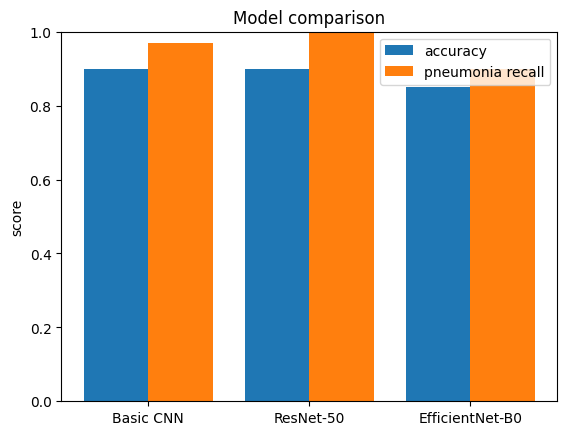

In [32]:
results = {
    "Basic CNN":       {"accuracy": 0.90, "pneumonia_recall": 0.97},
    "ResNet-50":       {"accuracy": 0.90, "pneumonia_recall": 1.00},
    "EfficientNet-B0": {"accuracy": 0.85, "pneumonia_recall": 0.90},
}

modelsList = list(results.keys())
acc = [results[m]["accuracy"] for m in modelsList]
rec = [results[m]["pneumonia_recall"] for m in modelsList]

x = np.arange(len(modelsList))
plt.bar(x - 0.2, acc, 0.4, label="accuracy")
plt.bar(x + 0.2, rec, 0.4, label="pneumonia recall")
plt.xticks(x, modelsList)
plt.ylim(0, 1)
plt.ylabel("score")
plt.title("Model comparison")
plt.legend()
plt.show()

Creates a Grad-CAM heatmap for a test image to show which area of the X-ray the model focused on

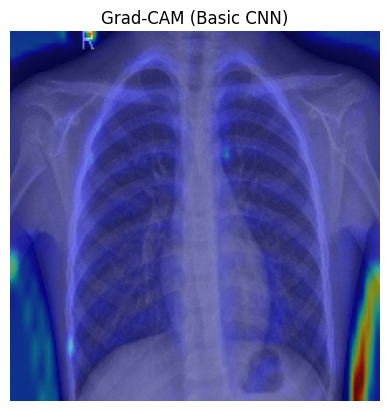

In [33]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

for images, labels in testDs.take(1):
    img = images[0:1]
    break

with tf.GradientTape() as tape:
    x = img
    convOut = None
    for l in cnnModel.layers:
        if isinstance(l, tf.keras.layers.InputLayer):
            continue
        x = l(x)
        if "conv" in l.name:
            convOut = x
            tape.watch(convOut)
    loss = x[:, 0]

grads = tape.gradient(loss, convOut)
pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
heatmap = tf.reduce_sum(convOut[0] * pooled, axis=-1)
heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
heatmap = tf.image.resize(heatmap[..., tf.newaxis], (224, 224)).numpy().squeeze()

plt.imshow(img[0].numpy())
plt.imshow(heatmap, cmap="jet", alpha=0.5)
plt.axis("off")
plt.title("Grad-CAM (Basic CNN)")
plt.show()

Creates a Grad-CAM heatmap for a test image to show which area of the X-ray the model focused on

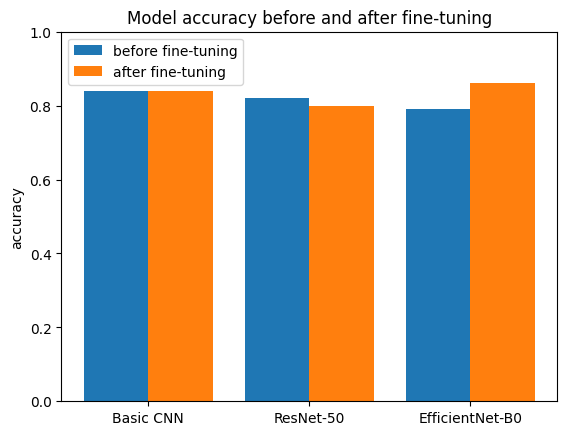

In [34]:
import numpy as np
import matplotlib.pyplot as plt

modelsList = ["Basic CNN", "ResNet-50", "EfficientNet-B0"]
beforeAcc = [0.84, 0.82, 0.79]
afterAcc = [0.84, 0.80, 0.86]

x = np.arange(len(modelsList))
plt.bar(x - 0.2, beforeAcc, 0.4, label="before fine-tuning")
plt.bar(x + 0.2, afterAcc, 0.4, label="after fine-tuning")
plt.xticks(x, modelsList)
plt.ylim(0, 1)
plt.ylabel("accuracy")
plt.title("Model accuracy before and after fine-tuning")
plt.legend()
plt.show()

Calculates the AUC and draws the ROC curve for the fine-tuned EfficientNet-B0

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 469ms/step
AUC: 0.965


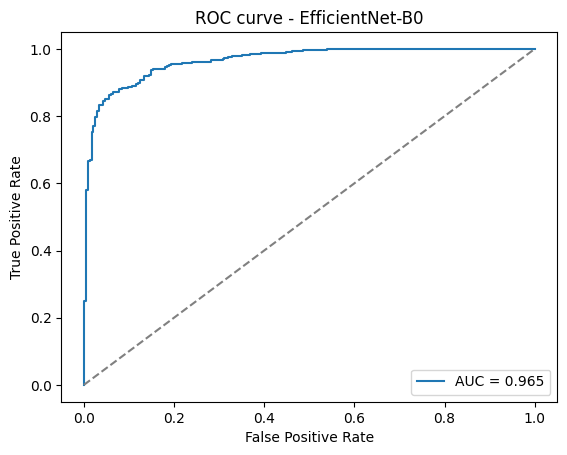

In [35]:
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import matplotlib.pyplot as plt

yTrue = np.concatenate([y.numpy() for x, y in testEff])
yProb = effModel.predict(testEff).ravel()

auc = roc_auc_score(yTrue, yProb)
print("AUC:", round(auc, 3))

fpr, tpr, thresholds = roc_curve(yTrue, yProb)
plt.plot(fpr, tpr, label="AUC = " + str(round(auc, 3)))
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve - EfficientNet-B0")
plt.legend()
plt.show()